# 02 · Do texts of the same kind have similar curves?

Every text becomes one **curve** per signal: the signal's raw value at each word (or token), in reading order.
For each of the 24 signals, the 25 curves are grouped into **2 clusters** by how similar they are, without telling
the algorithm which text is which kind:

- **distance between two texts**: DTW between their raw curves (nothing averaged or rescaled)
- **clustering**: k-medoids with 2 clusters, each centred on a real text
- **score**: how many texts end up in the cluster of their own kind

Reads what notebook 01 saved (no model run, a few minutes). Code: `analysis/cluster.py`; settings: `qwen_config.py`.

In [3]:
import os
import sys
import warnings
import tslearn
from pathlib import Path

os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
warnings.filterwarnings("ignore")
# make this folder's qwen_config.py and analysis/ importable, wherever Jupyter was started (e.g. the repo root)
QWEN7B_DIR = Path.cwd()
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "src/note_books/Qwen7B/qwen_config.py").exists():
        QWEN7B_DIR = folder / "src/note_books/Qwen7B"
        break
sys.path.insert(0, str(QWEN7B_DIR))

import analysis                                # also makes lca_core (repo root) importable
import matplotlib.pyplot as plt
import pandas as pd

from analysis.cluster import cluster, map_fit, score, text_map, tree, tree_in_two
from analysis.figures import (plot_dendrogram, plot_example_curves, plot_summary, plot_text_map, plot_text_map_3d,
                              save, save_html)
from analysis.signals import SIGNALS, curves_of, dataset_names, kinds_of, load_tables
from qwen_config import MAPS_TO_DRAW, MODEL_NAME, TABLES_DIR

names = dataset_names()
kinds = kinds_of(names)
word_tables, token_tables = load_tables(names, MODEL_NAME)
print(f"{len(names)} texts: {(kinds == 'factual').sum()} factual, {(kinds == 'creative').sum()} creative")

25 texts: 12 factual, 13 creative


## 1. What a curve looks like
GloVe distance between the model's top 5 guesses, at every noun/verb of one factual and one creative text.

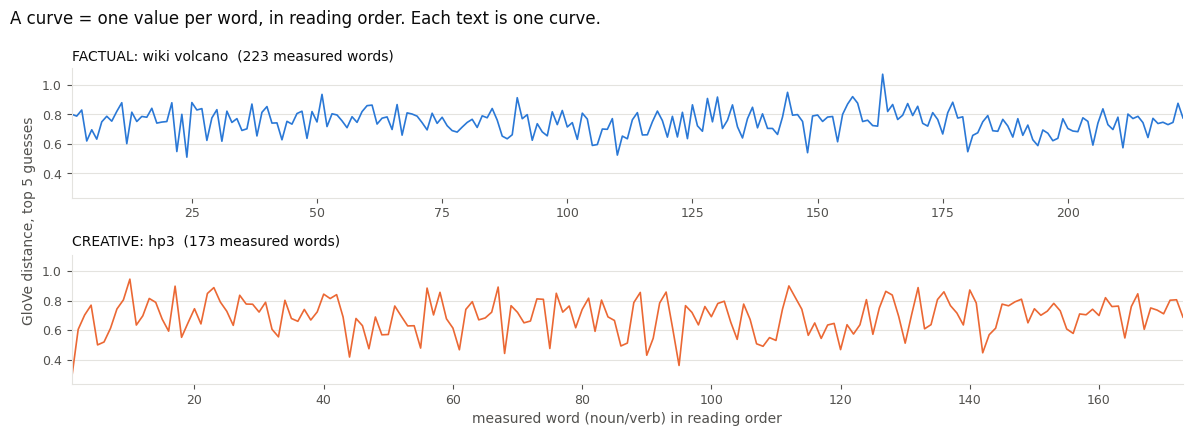

In [2]:
glove_top5 = None
for signal in SIGNALS:
    if signal.key == "glove_top5":
        glove_top5 = signal
examples = []
for name in ["factual_wiki_volcano", "creative_hp3"]:
    curve_of_text = curves_of(glove_top5, [name], word_tables, token_tables)[0]
    examples.append((name, kinds_of([name])[0], curve_of_text))
save(plot_example_curves(glove_top5.name, examples), "1_example_curves.png")
plt.show()

## 2. Cluster every signal

In [3]:
result_rows = []
clusterings = {}
for signal in SIGNALS:
    curves = curves_of(signal, names, word_tables, token_tables)
    labels, centres, distances = cluster(curves)
    clusterings[signal.key] = (labels, centres, distances)
    row = {"signal": signal.key, "name": signal.name, "family": signal.family}
    row.update(score(names, kinds, labels))
    row["tree cut in two: correct"] = score(names, kinds, tree_in_two(tree(distances)))["correct"]
    row["centre texts"] = f"{names[centres[0]]}, {names[centres[1]]}"
    result_rows.append(row)

results = pd.DataFrame(result_rows).sort_values("correct", ascending=False)
TABLES_DIR.mkdir(parents=True, exist_ok=True)
results.to_csv(TABLES_DIR / "clusters.csv", index=False)
pd.set_option("display.max_colwidth", 120)
results[["name", "correct", "factual correct", "creative correct", "tree cut in two: correct", "centre texts", "wrong cluster"]]

,name,correct,factual correct,creative correct,tree cut in two: correct,centre texts,wrong cluster
6,"GloVe distance, top 5 guesses",23,10,13,23,"factual_gut_candle, factual_gut_outline_science","factual_gut_candle, factual_wiki_vaccine"
5,"GloVe distance, top 3 guesses",22,12,10,22,"creative_hp4, factual_wiki_wordnet","creative_gut_sherlock, creative_hp2, creative_hp5"
7,"GloVe distance, likely guesses",22,9,13,20,"creative_gut_oz, factual_wiki_wordnet","factual_gut_candle, factual_gut_origin_species, factual_gut_outline_science"
11,"Qwen-embedding distance, likely guesses",22,9,13,20,"creative_gut_oz, factual_wiki_mitochondrion","factual_gut_candle, factual_gut_origin_species, factual_gut_outline_science"
12,surprisal per word,22,11,11,13,"creative_jokes_2, factual_gut_origin_species","creative_hp4, creative_jokes_for_all_occasions, factual_gut_outline_science"
8,"Qwen-embedding distance, top 1 vs real word",21,10,11,21,"creative_hp6, factual_gut_relativity","creative_hp2, creative_jokes_for_all_occasions, factual_gut_candle, factual_gut_origin_species"
4,"GloVe distance, top 1 vs real word",21,10,11,21,"creative_jokes_2, factual_gut_relativity","creative_hp2, creative_jokes_for_all_occasions, factual_gut_candle, factual_wiki_wordnet"
3,"LCA height, likely guesses",21,8,13,25,"creative_gut_oz, factual_wiki_volcano","factual_gut_relativity, factual_wiki_black_hole, factual_wiki_copper, factual_wiki_wordnet"
20,entropy per token,21,10,11,21,"factual_gut_candle, factual_wiki_vaccine","creative_gut_alice, creative_gut_oz, factual_gut_candle, factual_gut_outline_science"
19,max probability per token,21,10,11,21,"factual_gut_candle, factual_wiki_vaccine","creative_gut_alice, creative_gut_oz, factual_gut_candle, factual_gut_outline_science"


## 3. Every signal in one chart

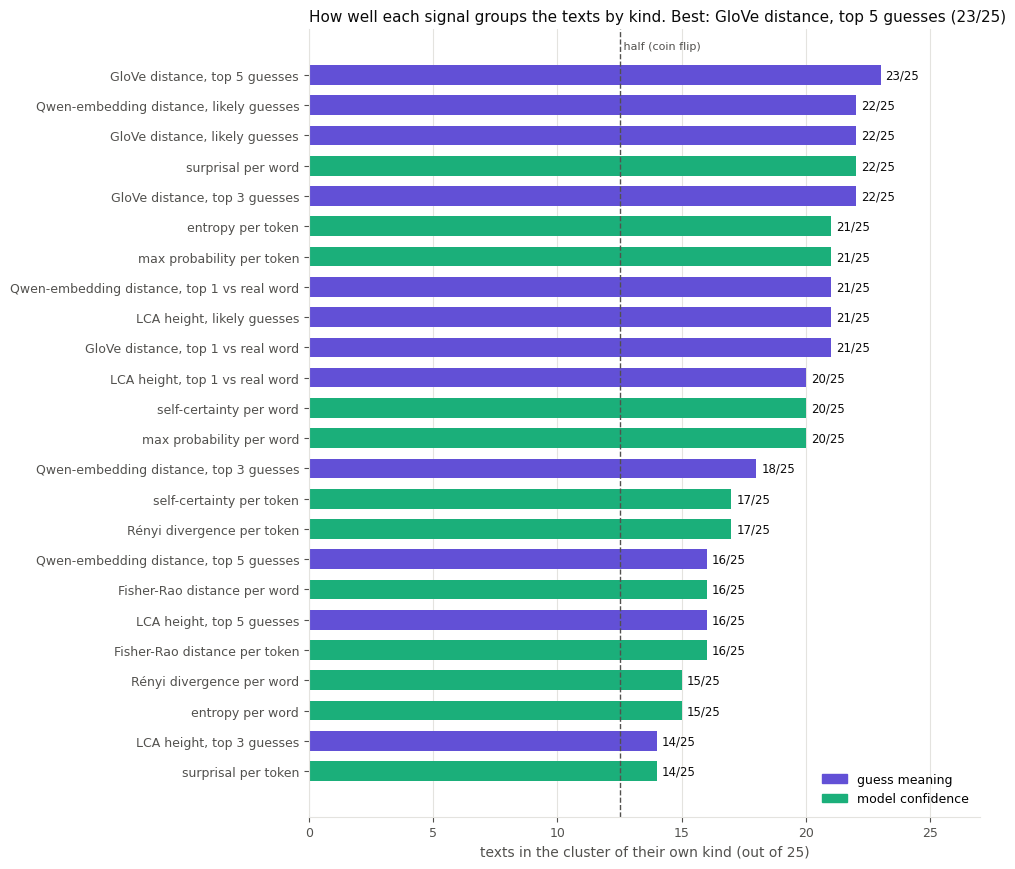

In [4]:
save(plot_summary(results), "2_all_signals.png")
plt.show()

## 4. Text maps of the best signals
Each dot is a text, placed so that texts with similar curves (small DTW distance) are close.

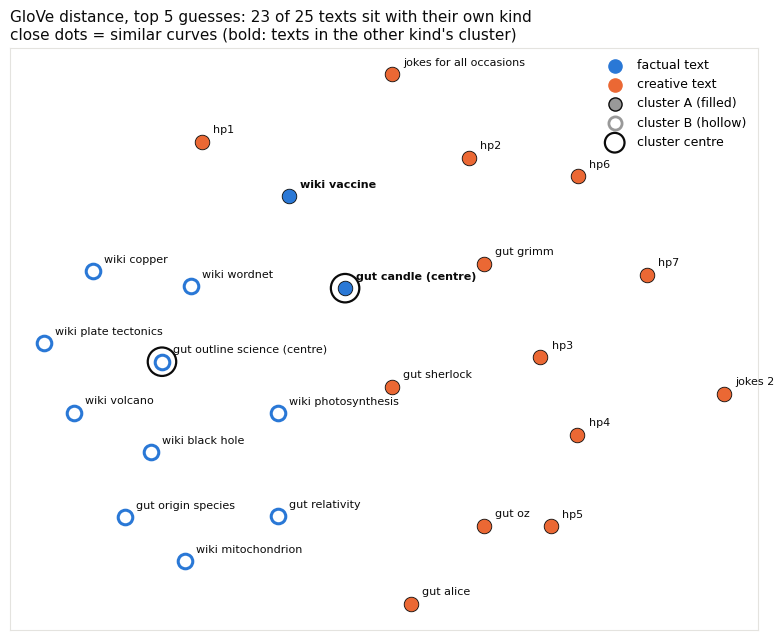

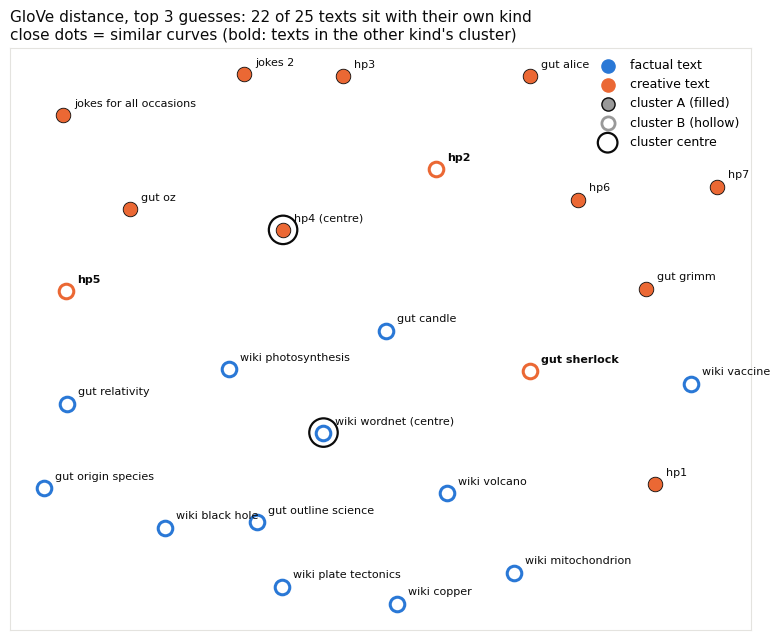

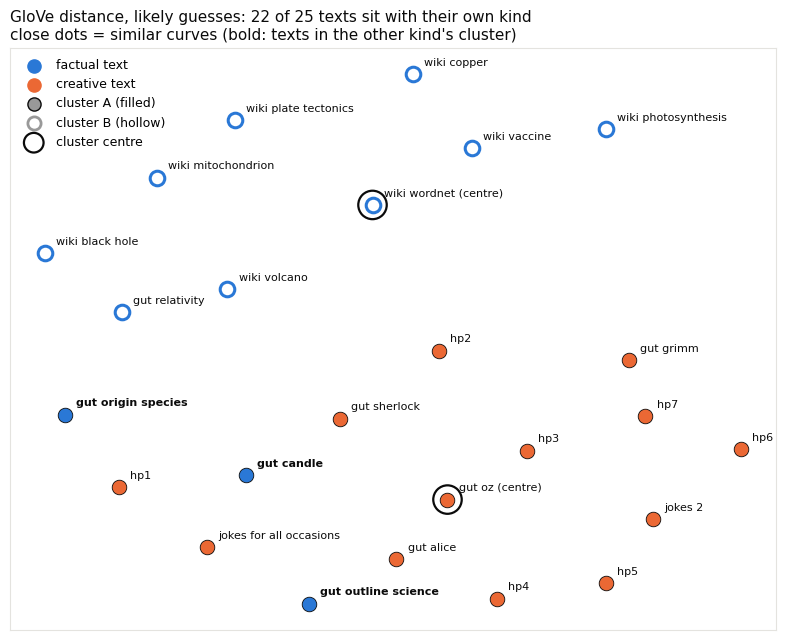

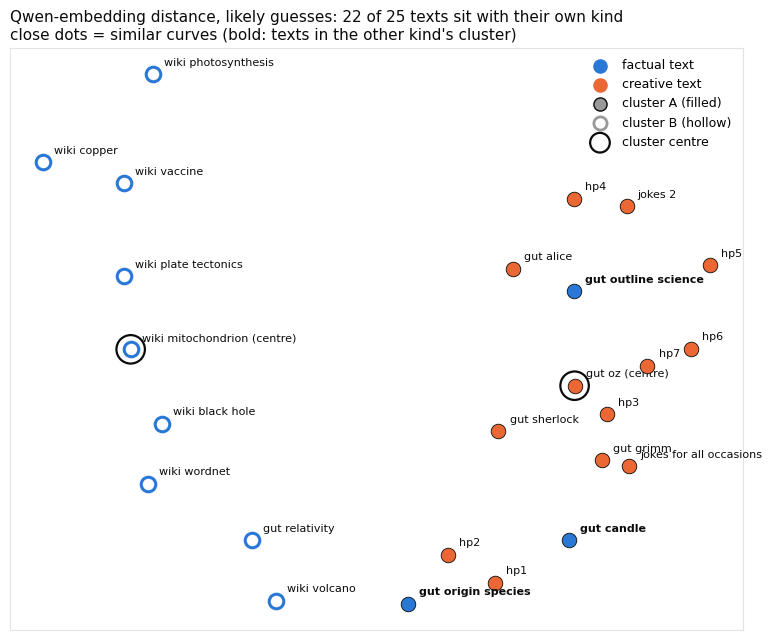

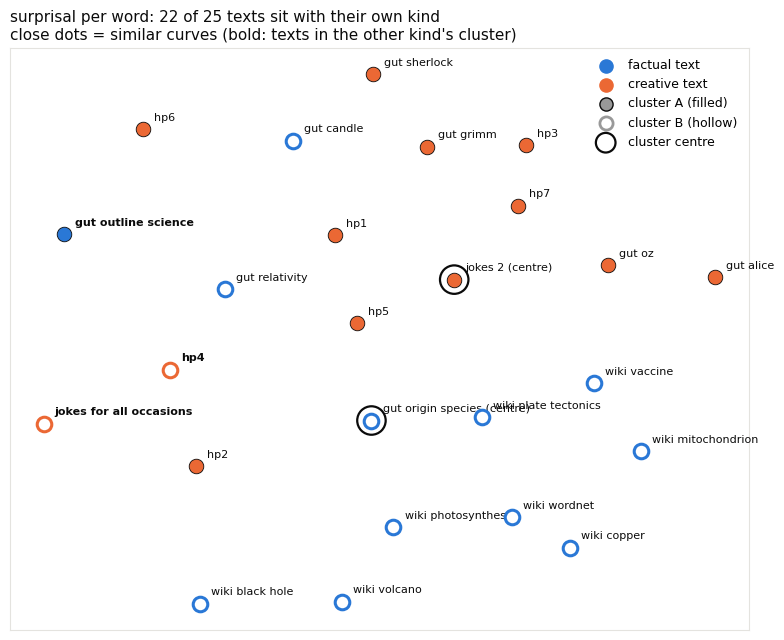

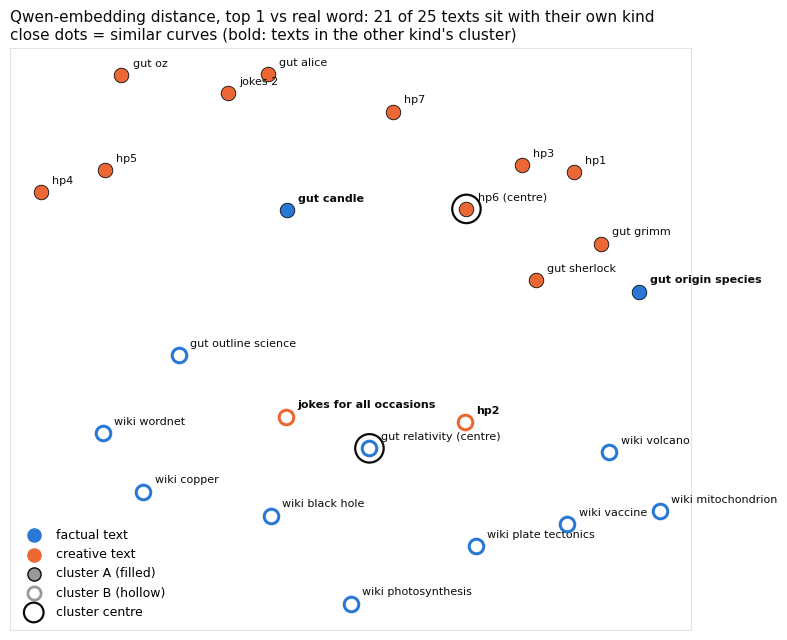

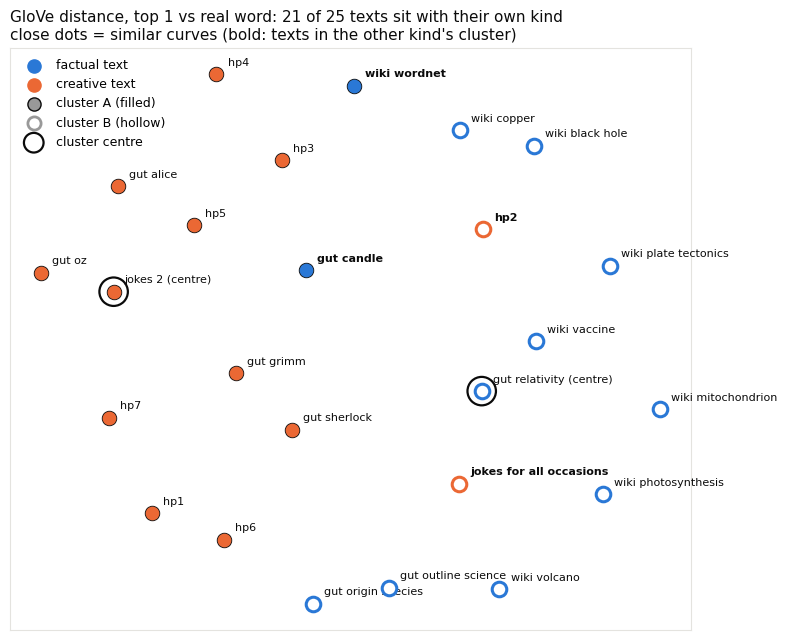

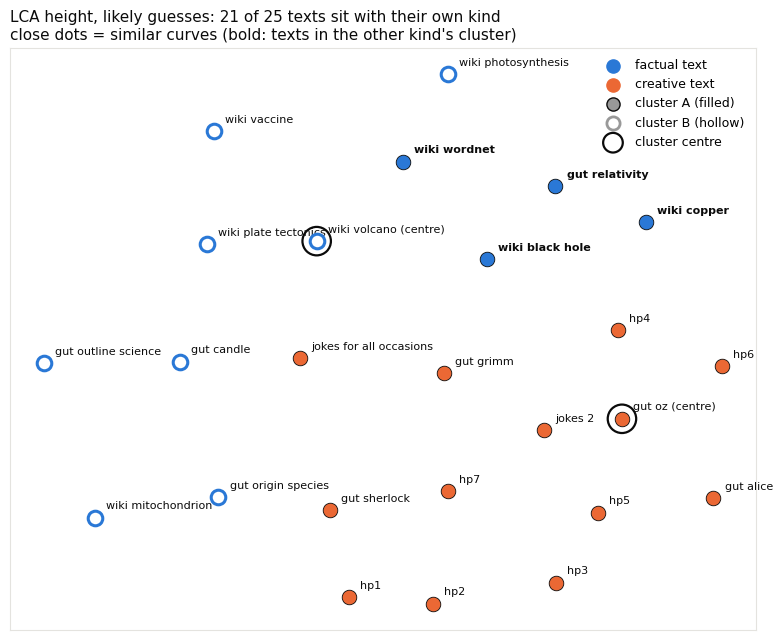

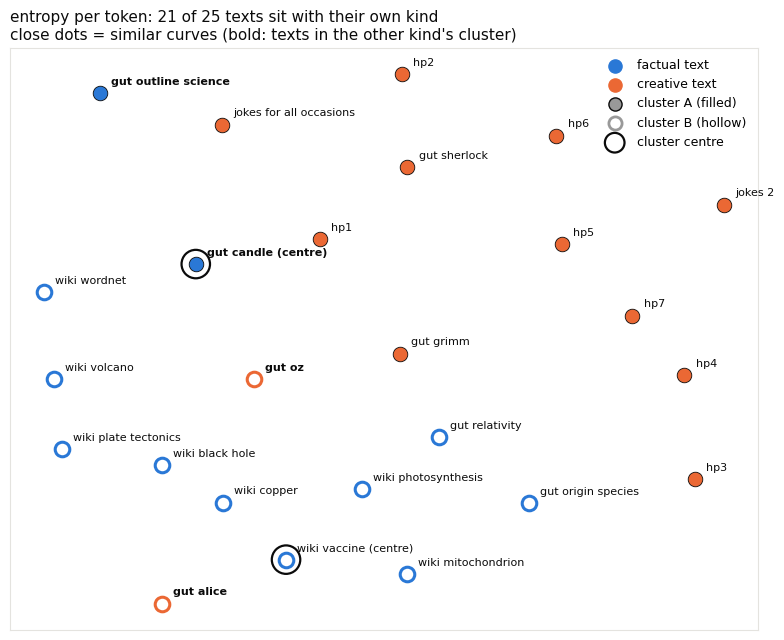

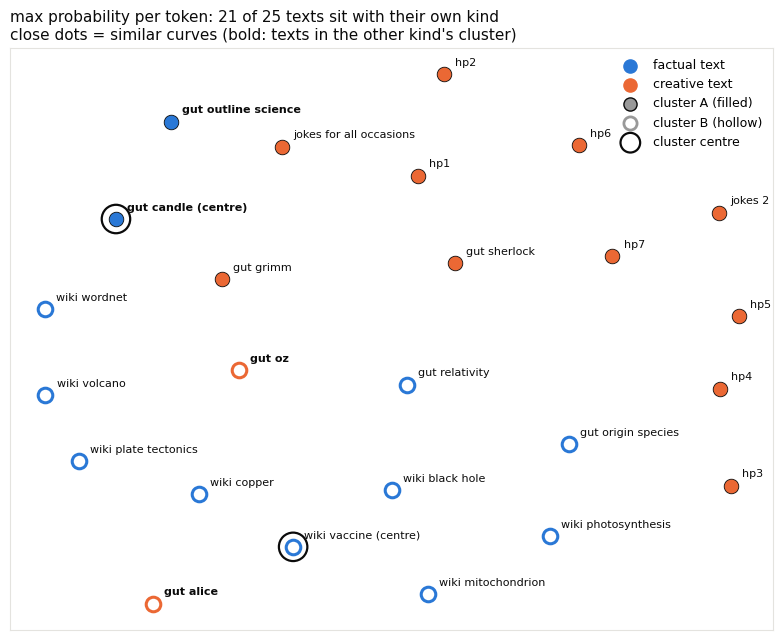

In [5]:
for map_number, (_index, result) in enumerate(results.head(MAPS_TO_DRAW).iterrows(), start=1):
    labels, centres, distances = clusterings[result["signal"]]
    figure = plot_text_map(result["name"], text_map(distances), names, kinds, labels, centres)
    save(figure, f"3_map_{map_number:02d}_{result['signal']}.png")
    plt.show()

## 5. Hierarchical clustering (dendrograms)
The same DTW distances, joined step by step: every text starts alone, and the two clusters whose *farthest* pair of
texts is closest are joined next (complete linkage, so nothing is averaged). Texts that join early (left) have
similar curves. Cutting the tree into its last two branches gives a second 2-cluster answer to compare with k-medoids.

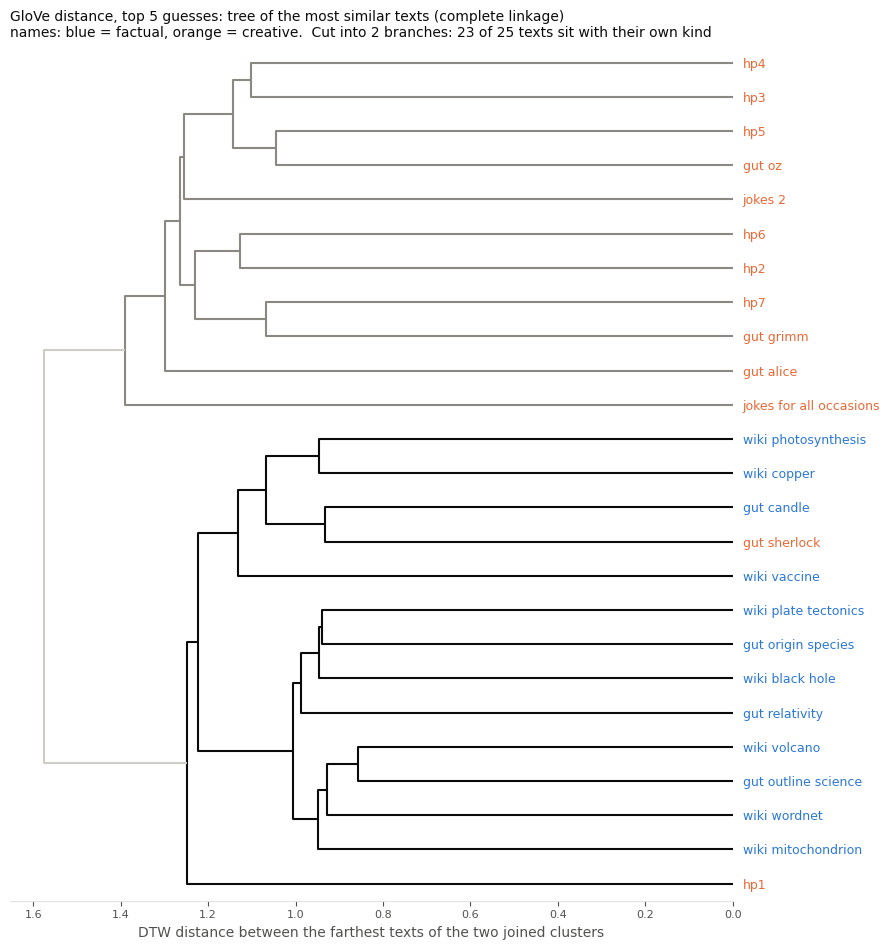

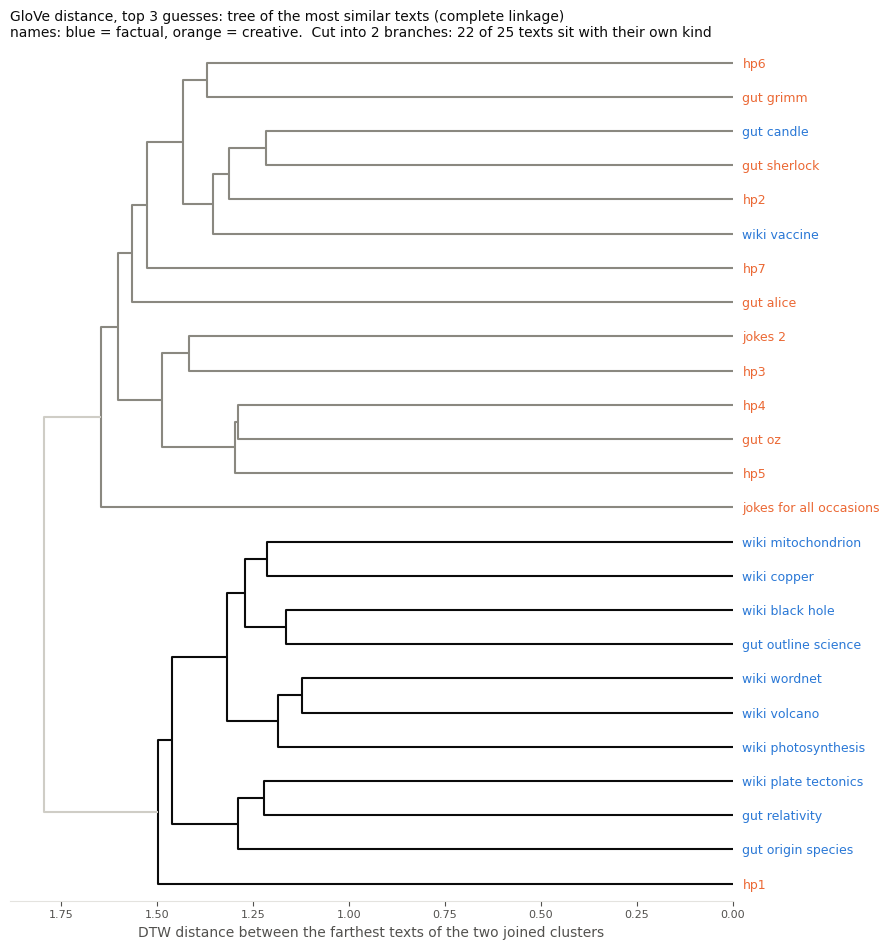

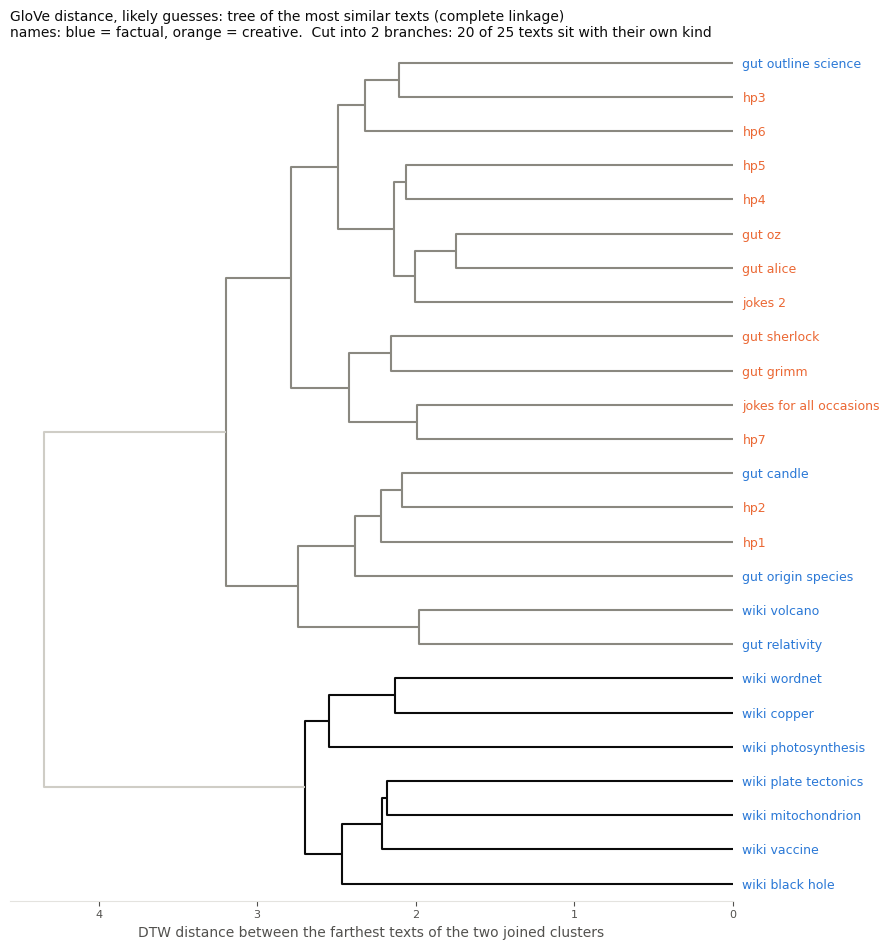

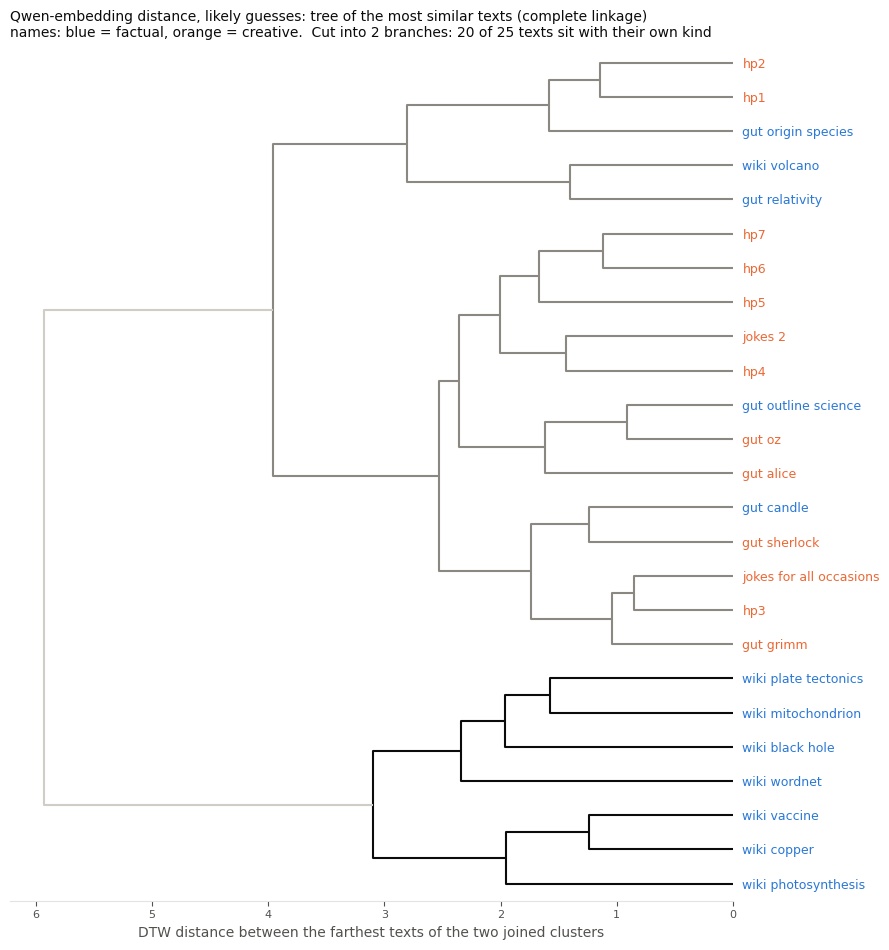

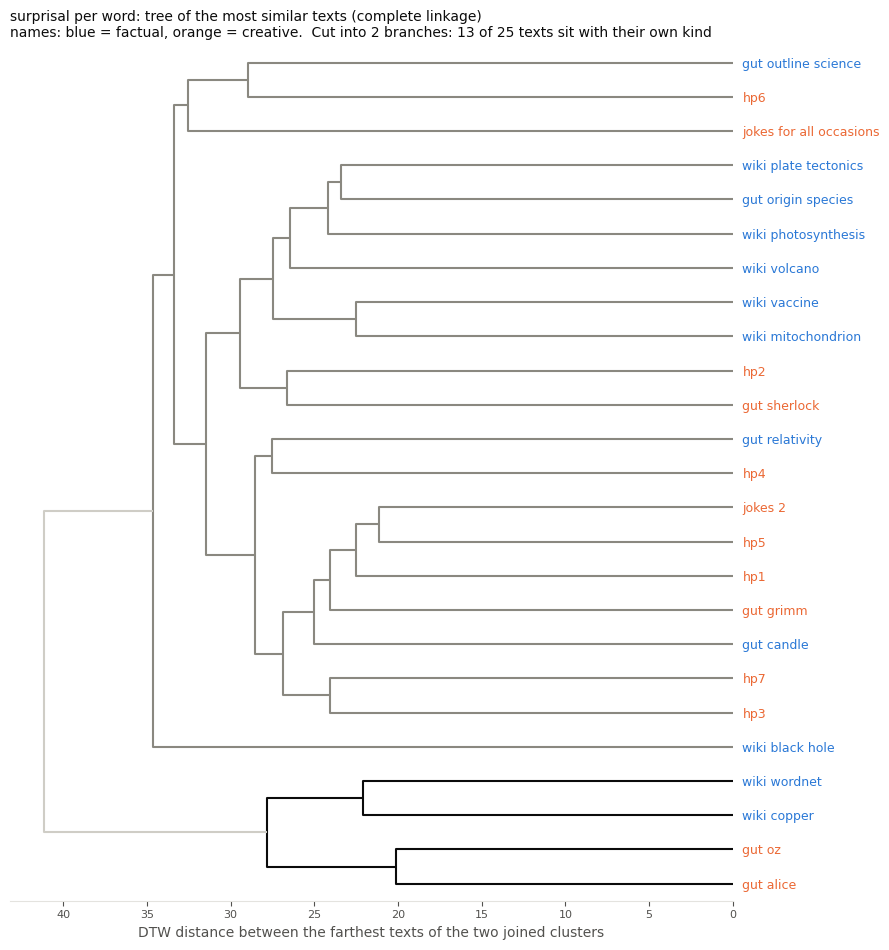

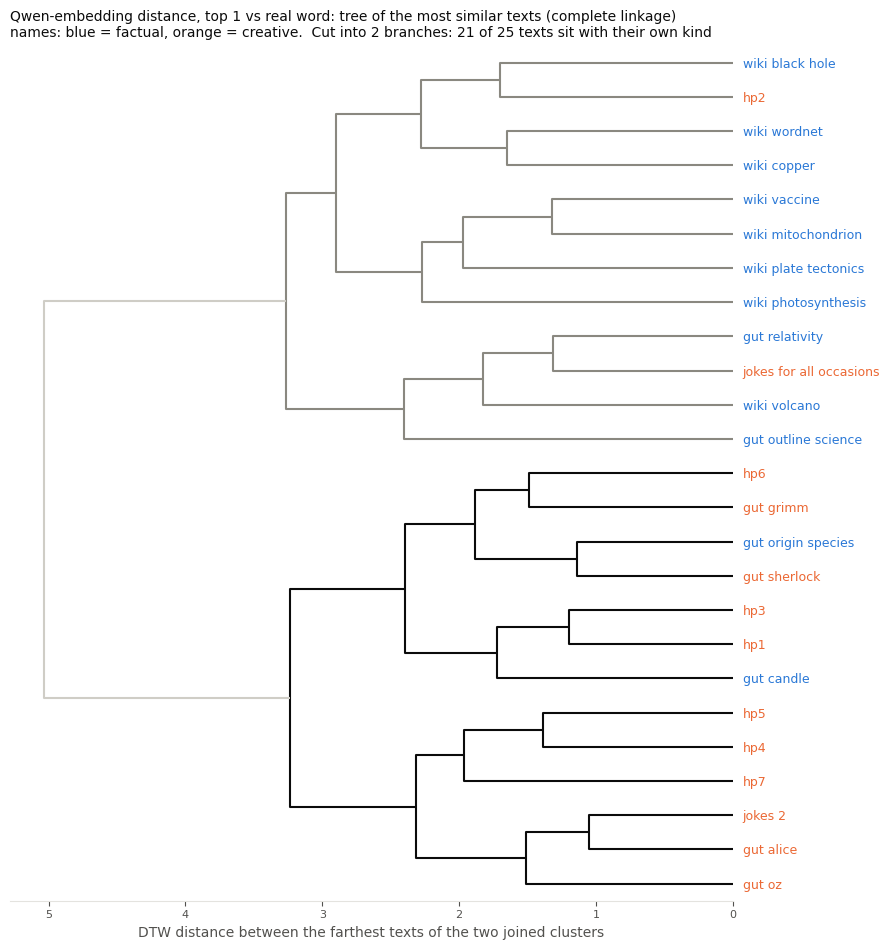

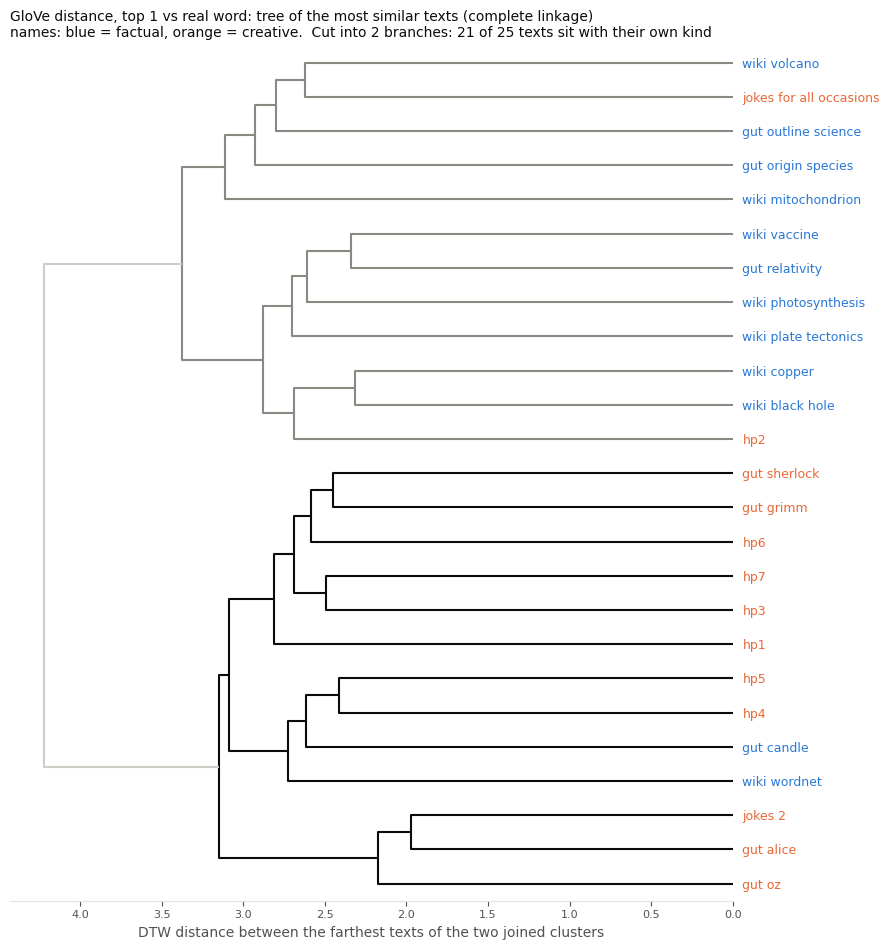

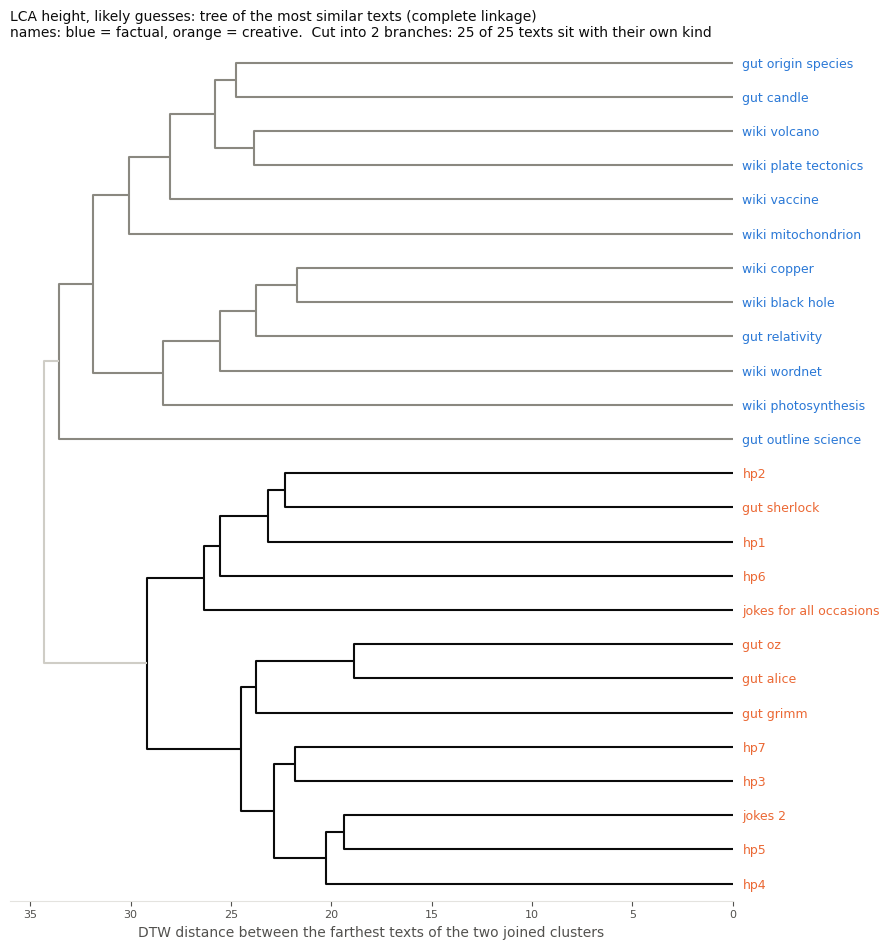

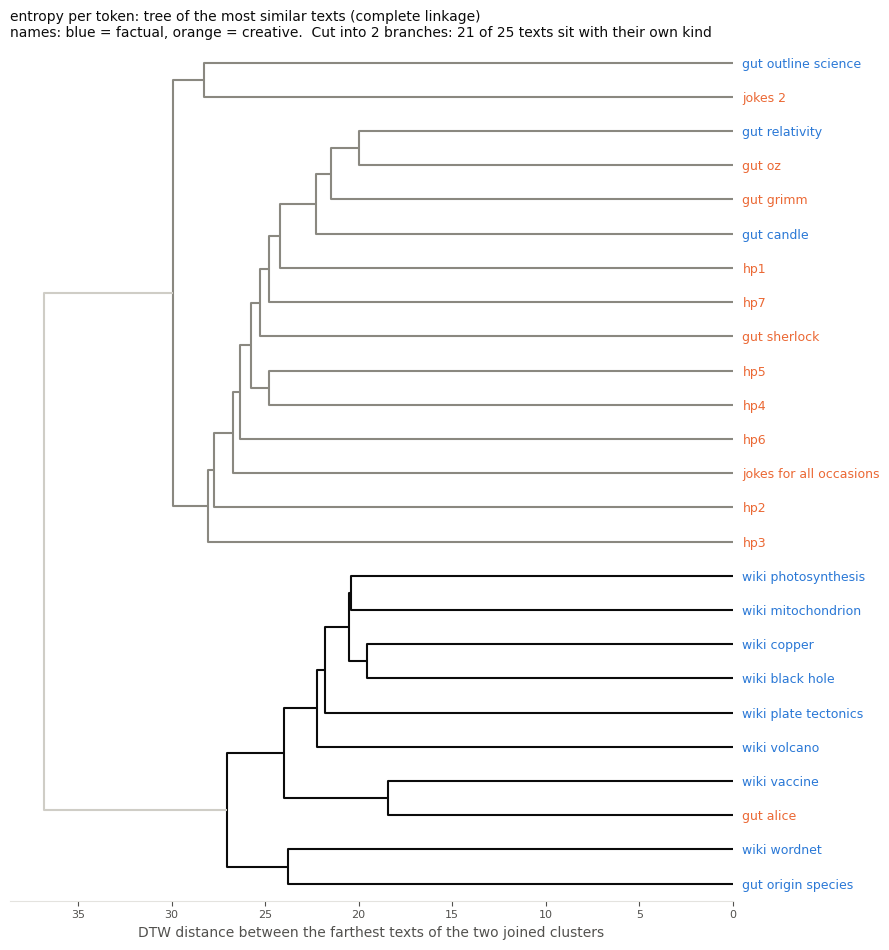

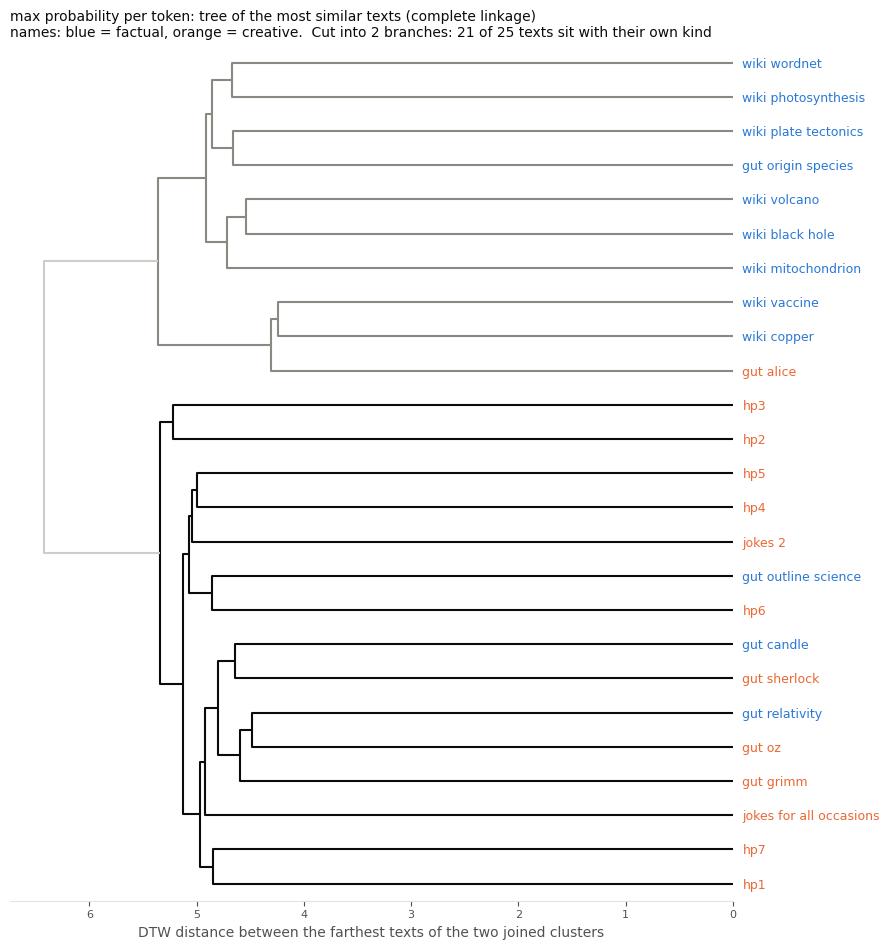

In [6]:
for map_number, (_index, result) in enumerate(results.head(MAPS_TO_DRAW).iterrows(), start=1):
    labels, centres, distances = clusterings[result["signal"]]
    joins = tree(distances)
    figure = plot_dendrogram(result["name"], joins, names, kinds, result["tree cut in two: correct"])
    save(figure, f"4_tree_{map_number:02d}_{result['signal']}.png")
    plt.show()

## 6. The same maps in 3D (interactive)
A third dimension gives MDS more room, so the map can fit the DTW distances better, but not always.
**Map fit** = correlation between distances on the map and the real DTW distances (1 = perfect).
Open the files in `results/figures/3d/` in a browser and drag to rotate.

In [7]:
fit_rows = []
for map_number, (_index, result) in enumerate(results.head(MAPS_TO_DRAW).iterrows(), start=1):
    labels, centres, distances = clusterings[result["signal"]]
    flat = text_map(distances, dimensions=2)
    solid = text_map(distances, dimensions=3)
    fit_2d = map_fit(distances, flat)
    fit_3d = map_fit(distances, solid)
    figure = plot_text_map_3d(result["name"], solid, names, kinds, labels, centres, fit_3d)
    save_html(figure, f"3d_map_{map_number:02d}_{result['signal']}.html")
    fit_rows.append({"signal": result["name"], "map fit 2D": fit_2d, "map fit 3D": fit_3d})
pd.DataFrame(fit_rows).round(2)

,signal,map fit 2D,map fit 3D
0,"GloVe distance, top 5 guesses",0.76,0.73
1,"GloVe distance, top 3 guesses",0.72,0.71
2,"GloVe distance, likely guesses",0.85,0.86
3,"Qwen-embedding distance, likely guesses",0.96,0.98
4,surprisal per word,0.64,0.73
5,"Qwen-embedding distance, top 1 vs real word",0.94,0.95
6,"GloVe distance, top 1 vs real word",0.84,0.81
7,"LCA height, likely guesses",0.71,0.73
8,entropy per token,0.72,0.71
9,max probability per token,0.67,0.60
